# XGBoost hybrid: performance on the eval year

An analysis of the shipped XGBoost hybrid (`models.xgboost_model`, `docs/xgboost_model.md`) on the
held-out eval year, 2025-10-20 → 2026-10-20: 1,448 forecast runs, one every 6 hours, each 72
hours long. The model was selected and fitted on the training years only. The eval year was scored
once by `python -m training.xgboost_model evaluate`; this notebook breaks that score down.

**The model:**

    forecast(k) = linear(k) + trees(lead k, last speed, recurrence means, linear(k) − last, 30 regressors)

- **linear(k)** is the shipped linear model (`linear_model.ipynb`), embedded in the hybrid's asset.
- **The trees** are 100 boosted trees of depth 4, pooled over all leads and trained on every hour of the 9 training years (2016-10 → 2025-10) with per-run TIMSE weights.
- **Missing regressors** take each split's learned default branch, except the solar-activity inputs that are never missing in training, which take their training medians.

**This is the 9-year hybrid** (`docs/xgboost_model.md`, "Nine years of history"):
- **Selection and taming** ran on six yearly walk-forward folds (2019-10 → 2025-10).
- **Taming:** the selected setting (minimum leaf weight 100) had leaves reached on a single training day, so the minimum leaf weight was raised to 10,000. That was the best fold score with every leaf reached on at least 30 training days (section 5.5).
- **History:** the 4-year hybrid's analysis (an earlier version of this notebook) had found a flare-count rule learned from one storm season; its scores are quoted from `docs/xgboost_model.md`.

**The question here is what the trees add to the linear model.** The hybrid is compared against:
- the **linear model** (its own anchor);
- the **final baseline** (the reference model and current submission);
- **persistence**.

1. **Scores:** overall, the per-run distribution, and forecasts along the year.
2. **By regime:** CME, stream arrival, quiet wind…
3. **Bias and level.**
4. **Stream arrivals:** the linear model's weakest regime.
5. **What the trees do:** the size of the corrections, the trees themselves, an ablation, the coronal-hole effect, and the taming.
6. **Through the year and the biggest differences.**
7. **Findings.**

**Conventions:**
- **Residual** = actual − forecast; negative means the model over-predicted.
- **Ratio** = a run's TIMSE for one model divided by another's for the same run. Below 1, the first model wins.
- **Correction** = hybrid − linear forecast, in km/s.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D

from feature_engineering.recurrence import last_observed, targets
from models.final_baseline import FinalBaseline
from models.linear_model import LinearModel
from models.xgboost_model import XGBoostModel
from training import solar_wind_events as ev
from training.datasets import EVAL_END, TRAIN_END, load_hourly
from training.evaluate import HORIZON, forecast_times, run_timse
from training.metrics import timse
from training.xgboost_model import config_path, feature_table

plt.rcParams.update(
    {"figure.figsize": (11, 3.5), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3}
)
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)

MODELS = ["hybrid", "linear_model", "final_baseline", "persistence"]
STYLE = {
    "hybrid": {"color": "#1baf7a", "lw": 1.8},
    "linear_model": {"color": "#eb6834", "lw": 1.5},
    "final_baseline": {"color": "#2a78d6", "lw": 1.3},
    "persistence": {"color": "#8a8984", "lw": 1.4, "ls": (0, (1, 1.5))},
}
REGIME_COLORS = {
    "CME": "#e34948", "possible CME": "#e87ba4", "stream arrival": "#eda100",
    "fast stream": "#6250d6", "slow wind": "#1baf7a", "intermediate": "#52514e",
}
WIN, LOSE = "#1baf7a", "#6250d6"
lead = np.arange(1, HORIZON + 1)


def model_legend(fig, extra=(), models=MODELS):
    handles = [Line2D([], [], **STYLE[m]) for m in models]
    labels = list(models)
    for handle, label in extra:
        handles.append(handle)
        labels.append(label)
    fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0),
               ncol=len(handles), frameon=False, fontsize=9)


def fmt(table):
    return table.map(lambda x: f"{x:.3g}" if isinstance(x, float) else x)

## 1. Scores

The hybrid is loaded from the shipped asset and evaluated with the numpy trees, as live. Its
regressors are built from the pulled history with the live availability rules. Three checks run
first:
- the embedded linear anchor equals the shipped linear model;
- the batch forecast equals the live `predict()` path on one run;
- the per-run scores reproduce `training.xgboost_model.evaluate`.

In [2]:
series = load_hourly()
values = series.to_numpy()
t0s = forecast_times()
pos = series.index.get_indexer(t0s)
actual = targets(values, pos)

hybrid = XGBoostModel.load()
linear = LinearModel.load()
INPUTS = list(hybrid.input_features)
TREE_FEATURES = list(hybrid.config.features)
table = feature_table(t0s, tuple(dict.fromkeys(INPUTS + list(linear.config.features))))
x = table[INPUTS].to_numpy(dtype=float)
x_lin = table[list(linear.config.features)].to_numpy(dtype=float)

forecasts = {
    "hybrid": hybrid.forecast(values, pos, x),
    "linear_model": linear.forecast(values, pos, x_lin),
    "final_baseline": FinalBaseline.load().forecast(values, pos),
    "persistence": np.repeat(last_observed(values, pos)[:, None], HORIZON, 1),
}
anchor = hybrid.anchor(values, pos, x)
assert np.allclose(anchor, forecasts["linear_model"]), "the anchor is the shipped linear model"
i = 700
row = dict(zip(INPUTS, x[i], strict=True))
assert np.allclose(hybrid.predict(series.iloc[: pos[i]], row), forecasts["hybrid"][i])
correction = forecasts["hybrid"] - forecasts["linear_model"]

residuals = {m: actual - f for m, f in forecasts.items()}
run_scores = pd.DataFrame({m: run_timse(forecasts[m], actual) for m in MODELS}, index=t0s)
vs_lin = run_scores["hybrid"] / run_scores["linear_model"]
vs_base = run_scores["hybrid"] / run_scores["final_baseline"]
lin_vs_base = run_scores["linear_model"] / run_scores["final_baseline"]

overall = pd.DataFrame({
    m: {
        "pooled TIMSE": timse(actual, forecasts[m]),
        "per-run mean": run_scores[m].mean(),
        "per-run median": run_scores[m].median(),
        "per-run p90": run_scores[m].quantile(0.9),
        "RMSE": float(np.sqrt(np.nanmean(residuals[m] ** 2))),
        "beats persistence": (run_scores[m] < run_scores["persistence"]).mean(),
    }
    for m in MODELS
}).T
print(f"{len(t0s)} runs; the hybrid beats the linear model in {(vs_lin < 1).mean():.0%} of runs "
      f"and the final baseline in {(vs_base < 1).mean():.0%}")
print(f"tree inputs missing (share of runs): {np.isnan(x).any(axis=1).mean():.1%} of runs miss at "
      f"least one; worst: {table[INPUTS].isna().mean().sort_values().iloc[-3:].round(3).to_dict()}")
fmt(overall)

1448 runs; the hybrid beats the linear model in 62% of runs and the final baseline in 66%
tree inputs missing (share of runs): 25.3% of runs miss at least one; worst: {'ch_east_at_24h': 0.194, 'ch_cm_at_48h': 0.197, 'ch_cm_at_72h': 0.2}


,pooled TIMSE,per-run mean,per-run median,per-run p90,RMSE,beats persistence
hybrid,4.73e+07,2.22e+06,6.45e+05,3.53e+06,101,0.624
linear_model,4.82e+07,2.34e+06,6.67e+05,3.43e+06,103,0.584
final_baseline,5.58e+07,2.59e+06,8.45e+05,3.21e+06,110,0.532
persistence,8.13e+07,5.57e+06,7.76e+05,1.38e+07,110,0


**The per-run distribution.** Per-run TIMSE quantiles for the three models. The scatter puts each
run's hybrid TIMSE against the linear model's (below the diagonal, the hybrid wins). The histogram
shows the per-run ratio: the trees' corrections are small, so most runs sit close to 1.

,hybrid,linear_model,final_baseline,hybrid / linear,hybrid / baseline
p10,1.79e+05,1.95e+05,2.48e+05,0.917,0.719
p25,3.21e+05,3.61e+05,4.39e+05,0.889,0.732
p50,6.45e+05,6.67e+05,8.45e+05,0.966,0.764
p75,1.5e+06,1.41e+06,1.64e+06,1.07,0.916
p90,3.53e+06,3.43e+06,3.21e+06,1.03,1.1
p95,6.36e+06,6.92e+06,7.99e+06,0.92,0.796
p99,4.23e+07,3.61e+07,4.67e+07,1.17,0.905


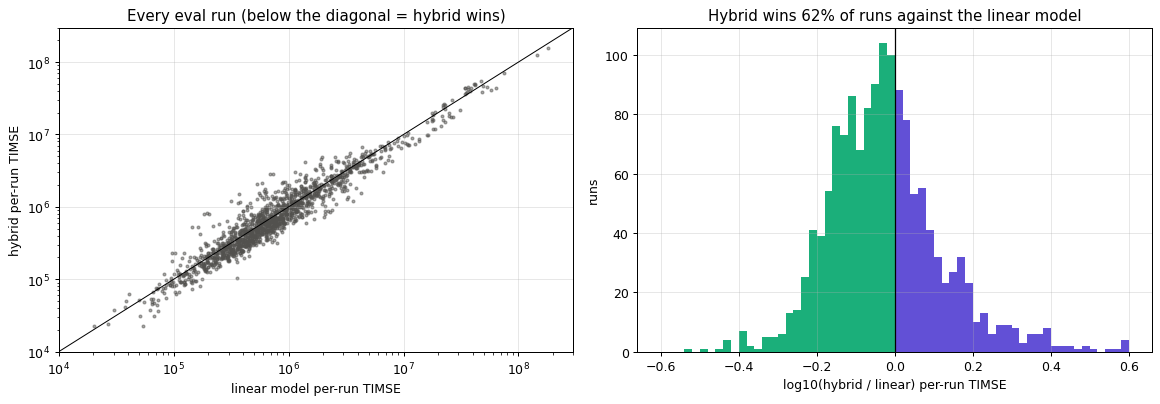

In [3]:
qs = [0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]
quant = pd.DataFrame({m: run_scores[m].quantile(qs) for m in MODELS[:3]})
quant["hybrid / linear"] = quant["hybrid"] / quant["linear_model"]
quant["hybrid / baseline"] = quant["hybrid"] / quant["final_baseline"]
quant.index = [f"p{int(q * 100)}" for q in qs]
display(fmt(quant))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
ax = axes[0]
lo, hi = 1e4, 3e8
ax.plot([lo, hi], [lo, hi], color="k", lw=0.8)
ax.scatter(run_scores["linear_model"], run_scores["hybrid"], s=5, alpha=0.5, color="#52514e")
ax.set(xscale="log", yscale="log", xlim=(lo, hi), ylim=(lo, hi),
       xlabel="linear model per-run TIMSE", ylabel="hybrid per-run TIMSE",
       title="Every eval run (below the diagonal = hybrid wins)")
ax = axes[1]
r = np.log10(vs_lin.dropna())
bins = np.linspace(-0.6, 0.6, 61)
ax.hist(r[r < 0], bins=bins, color=WIN)
ax.hist(r[r >= 0], bins=bins, color=LOSE)
ax.axvline(0, color="k", lw=1)
ax.set(xlabel="log10(hybrid / linear) per-run TIMSE", ylabel="runs",
       title=f"Hybrid wins {(r < 0).mean():.0%} of runs against the linear model")
fig.tight_layout()

**Forecasts along the year.** The observed speed against the hybrid's and the linear model's
forecasts: the first eval run, then one run every 3 days. Runs are 72 h long, so the forecasts tile
the year without overlapping. Dotted lines mark each run's `t0`. Where the two forecasts differ, the
trees made a correction.

121 non-overlapping runs; per-run mean TIMSE: {'hybrid': '1.93e+06', 'linear_model': '1.87e+06', 'final_baseline': '2.17e+06', 'persistence': '4.4e+06'}


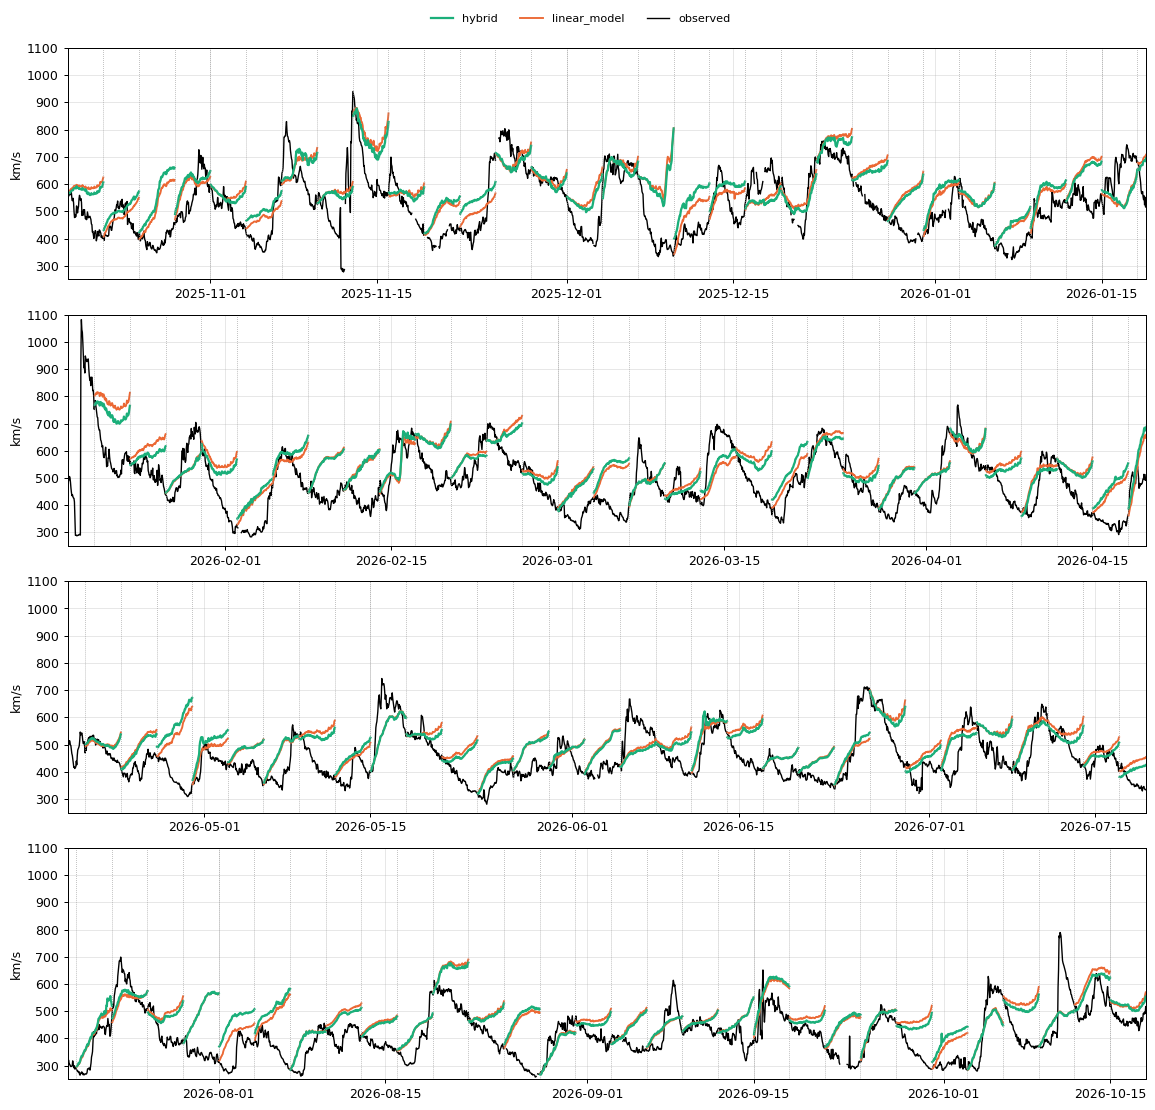

In [4]:
STRIDE = 72 // 6  # runs are 6-hourly; every 12th run is 3 days apart
tiled = np.arange(0, len(t0s), STRIDE)
tiled_times = [t0s[i] + pd.to_timedelta(lead, unit="h") for i in tiled]
valid_hours = tiled_times[0].append(tiled_times[1:])
# consecutive runs: no overlap and no gap
assert valid_hours.is_unique and (np.diff(valid_hours.asi8) == 3600 * 10**9).all()

tiled_scores = run_scores.iloc[tiled]
print(f"{len(tiled)} non-overlapping runs; per-run mean TIMSE:",
      {m: f"{tiled_scores[m].mean():.3g}" for m in MODELS})

quarters = pd.date_range(t0s[0], t0s[tiled[-1]] + pd.Timedelta(hours=HORIZON + 1), periods=5)
fig, axes = plt.subplots(4, 1, figsize=(13, 12))
for k, ax in enumerate(axes):
    lo, hi = quarters[k], quarters[k + 1]
    obs = series[lo:hi]
    ax.plot(obs.index, obs, color="k", lw=1.1)
    for r, i in enumerate(tiled):  # one line per run, so separate runs aren't joined
        if lo <= t0s[i] < hi:
            for m in ("linear_model", "hybrid"):
                ax.plot(tiled_times[r], forecasts[m][i], **STYLE[m])
    for t in t0s[tiled][(t0s[tiled] >= lo) & (t0s[tiled] < hi)]:
        ax.axvline(t, color="0.6", lw=0.6, ls=":")
    ax.set(ylabel="km/s", xlim=(lo, hi), ylim=(250, 1100))
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=1.1), "observed")],
             models=["hybrid", "linear_model"])

## 2. By regime

Runs are labelled by what happened during their 72 target hours (`ev.classify_runs`), as in the
other analyses. For each regime:
- **runs** and their per-run mean TIMSE for each model;
- **share of the change vs linear:** the regime's share of the overall change in the sum of per-run TIMSE, hybrid minus linear (negative is a gain for the hybrid);
- **median ratios and win rates:** hybrid / linear and hybrid / baseline;
- **pooled TIMSE** of the hybrid relative to the linear model.

In [5]:
cond_start = pd.Timestamp("2025-07-01T00:00Z")
minutes = ev.load_conditions(cond_start, EVAL_END)
hourly = minutes.resample("h").mean().reindex(
    pd.date_range(cond_start, EVAL_END, freq="h", inclusive="left", name="Time")
)
events = ev.detect_icmes(hourly, ev.detect_shocks(minutes))
cme = ev.cme_mask(hourly.index, events)
possible = ev.cme_mask(hourly.index, events, ("possible ICME",))
arrivals = ev.detect_stream_arrivals(hourly["speed"], cme | possible)
cme_hours = cme.reindex(series.index, fill_value=False)
possible_hours = possible.reindex(series.index, fill_value=False)
regime = pd.Series(ev.classify_runs(t0s, actual, cme_hours, arrivals, possible_hours),
                   index=t0s, name="regime")
no_cme = regime.isin(ev.NO_CME).to_numpy()

diff = run_scores["hybrid"] - run_scores["linear_model"]
total_change = diff.sum()


def regime_row(sel):
    return {
        "runs": int(sel.sum()),
        "hybrid mean": run_scores.loc[sel, "hybrid"].mean(),
        "linear mean": run_scores.loc[sel, "linear_model"].mean(),
        "baseline mean": run_scores.loc[sel, "final_baseline"].mean(),
        "share of change vs linear": diff[sel].sum() / abs(total_change),
        "median hybrid / linear": vs_lin[sel].median(),
        "hybrid beats linear": (vs_lin[sel] < 1).mean(),
        "median hybrid / baseline": vs_base[sel].median(),
        "hybrid beats baseline": (vs_base[sel] < 1).mean(),
        "pooled hybrid / linear": timse(actual[sel], forecasts["hybrid"][sel])
        / timse(actual[sel], forecasts["linear_model"][sel]),
    }


rows = {r: regime_row((regime == r).to_numpy()) for r in ev.REGIMES}
rows["all no-CME"] = regime_row(no_cme)
rows["all"] = regime_row(np.ones(len(t0s), dtype=bool))
by_regime = pd.DataFrame(rows).T
by_regime["runs"] = by_regime["runs"].astype(int)
fmt(by_regime)

[solar_wind_events] plasma: 476/476 days


[solar_wind_events] mag: 476/476 days


,runs,hybrid mean,linear mean,baseline mean,share of change vs linear,median hybrid / linear,hybrid beats linear,median hybrid / baseline,hybrid beats baseline,pooled hybrid / linear
CME,295,6.54e+06,6.85e+06,7.78e+06,-0.535,0.969,0.532,0.905,0.62,0.98
possible CME,81,5.41e+05,5.86e+05,6.88e+05,-0.0209,0.866,0.753,0.665,0.765,0.942
stream arrival,304,2.28e+06,2.45e+06,2.17e+06,-0.292,1.01,0.48,0.988,0.516,0.793
fast stream,105,1.1e+06,1.22e+06,1.45e+06,-0.0738,0.869,0.752,0.793,0.657,0.891
slow wind,186,6.32e+05,6.17e+05,9.06e+05,0.0165,0.915,0.677,0.637,0.812,1.08
intermediate,477,6.68e+05,7.03e+05,8.81e+05,-0.0946,0.889,0.69,0.711,0.698,0.902
all no-CME,1072,1.16e+06,1.23e+06,1.31e+06,-0.444,0.927,0.634,0.8,0.662,0.826
all,1448,2.22e+06,2.34e+06,2.59e+06,-1,0.928,0.62,0.817,0.66,0.982


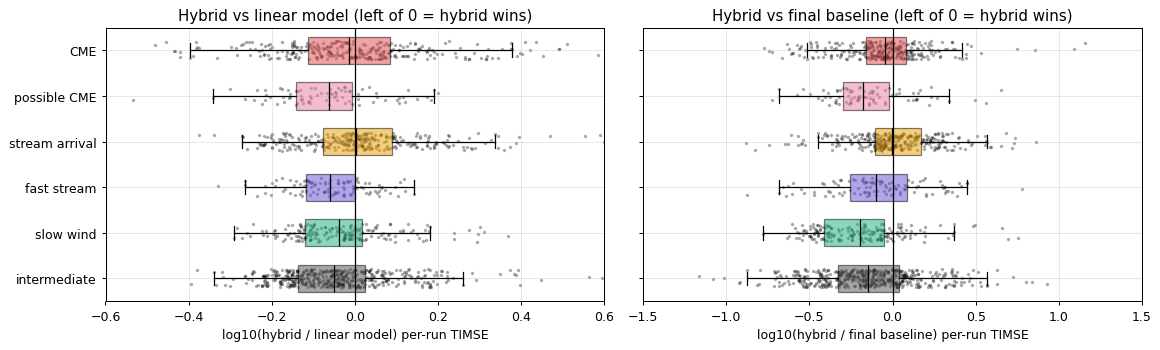

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
order = ev.REGIMES
for ax, (r, label, lim) in zip(
        axes, [(vs_lin, "linear model", 0.6), (vs_base, "final baseline", 1.5)], strict=True):
    data = [np.log10(r[(regime == g).to_numpy()].dropna()) for g in order]
    parts = ax.boxplot(data, vert=False, showfliers=False, patch_artist=True,
                       widths=0.6, medianprops={"color": "k"})
    ax.set_yticks(range(1, len(order) + 1), order)
    for patch, g in zip(parts["boxes"], order, strict=True):
        patch.set(facecolor=REGIME_COLORS[g], alpha=0.5)
    rng = np.random.default_rng(0)
    for k, d in enumerate(data, 1):
        ax.scatter(d, k + rng.uniform(-0.2, 0.2, len(d)), s=3, color="k", alpha=0.25)
    ax.axvline(0, color="k", lw=1)
    ax.set(xlabel=f"log10(hybrid / {label}) per-run TIMSE", xlim=(-lim, lim),
           title=f"Hybrid vs {label} (left of 0 = hybrid wins)")
axes[0].invert_yaxis()
fig.tight_layout()

## 3. Bias and level

Mean residual and RMSE by lead for each regime (top: mean residual, negative = over-forecast;
bottom: RMSE). Then the forecast distribution at 24 h and 72 h against the observed speeds: both
earlier models rarely forecast slow wind at 72 h.

bias 6 h RMSE 6 h bias 24 h RMSE 24 h bias 72 h RMSE 72 h
CME            hybrid              -26       76     -54.5       119     -78.9       141
               linear_model      -16.2     74.3     -45.1       118     -76.6       145
               final_baseline      -10       74     -42.8       122     -57.7       131
possible CME   hybrid            -9.97     31.1     -45.1      69.4      -134       147
               linear_model      -12.6     31.9     -50.5        75      -147       159
               final_baseline    -15.1     35.6     -62.7      84.6      -129       143
stream arrival hybrid            -19.1     45.6     -42.9      95.3       -15      86.1
               linear_model      -8.44     40.1     -32.3      90.3     -6.89      83.9
               final_baseline    -9.44     46.1     -49.1       103     -14.3      80.7
fast stream    hybrid           0.0997     46.2      -1.7      74.8      -148       165
               linear_model       2.28     47.8      -1.2      77.2      -163       181
               final_baseline     7.82     49.3      13.4      77.6      -133       158
slow wind      hybrid            -15.5     26.4       -72      81.6      -151       161
               linear_model        -17     24.7     -73.7      82.5      -154       163
               final_baseline    -24.6     31.7     -97.8       108      -166       175
intermediate   hybrid            -11.8     33.2     -58.2      76.6      -153       168
               linear_model      -12.5     30.5     -60.1      76.6      -162       178
               final_baseline    -17.5     35.1     -74.8      90.1      -159       174

p1  p10 median  p90
24 h hybrid          368  423    505  631
     linear_model    371  423    501  630
     final_baseline  388  440    524  617
     observed        281  349    448  623
72 h hybrid          427  486    568  672
     linear_model    433  491    569  677
     final_baseline  447  502    567  655
     observed        281  349    448  623

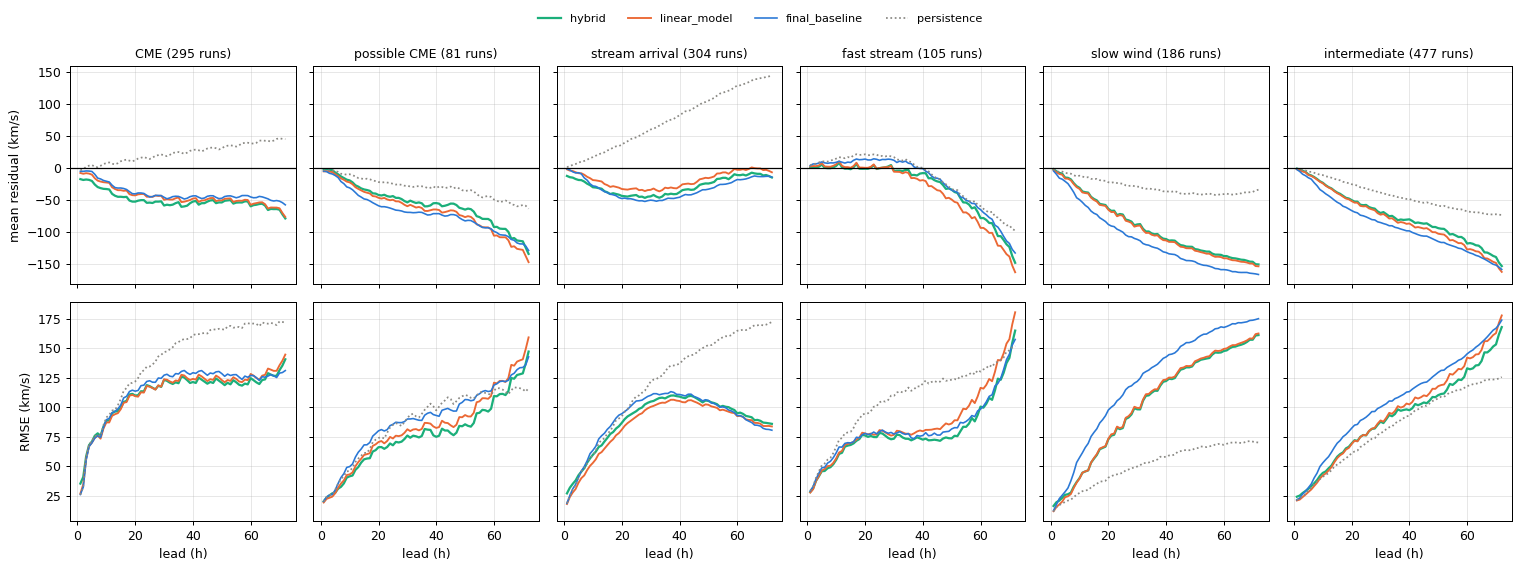

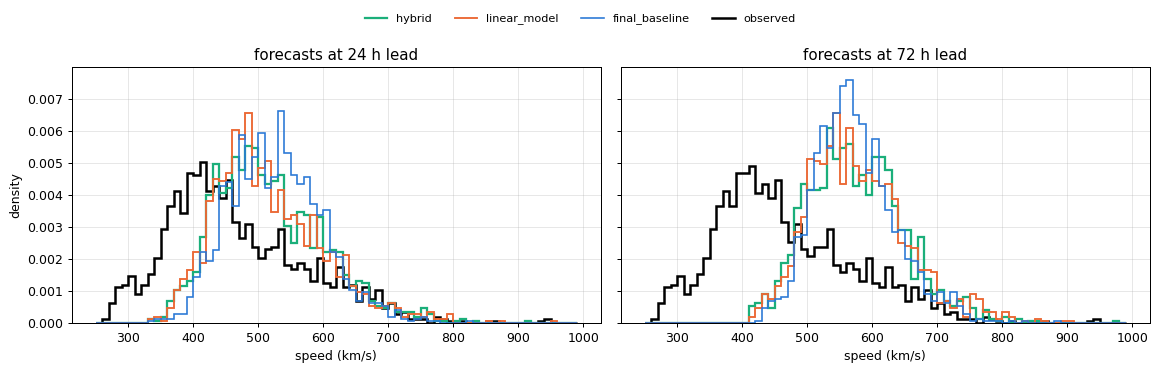

In [7]:
fig, axes = plt.subplots(2, len(ev.REGIMES), figsize=(17, 6), sharex=True, sharey="row")
bias_rows = {}
for col, g in enumerate(ev.REGIMES):
    sel = (regime == g).to_numpy()
    for m in MODELS:
        r = residuals[m][sel]
        axes[0, col].plot(lead, np.nanmean(r, axis=0), **STYLE[m])
        axes[1, col].plot(lead, np.sqrt(np.nanmean(r**2, axis=0)), **STYLE[m])
        if m != "persistence":
            for k in (6, 24, 72):
                bias_rows[(g, m)] = bias_rows.get((g, m), {}) | {
                    f"bias {k} h": np.nanmean(r[:, k - 1]),
                    f"RMSE {k} h": np.sqrt(np.nanmean(r[:, k - 1] ** 2)),
                }
    axes[0, col].axhline(0, color="k", lw=1)
    axes[0, col].set_title(f"{g} ({sel.sum()} runs)", fontsize=10)
    axes[1, col].set_xlabel("lead (h)")
axes[0, 0].set_ylabel("mean residual (km/s)")
axes[1, 0].set_ylabel("RMSE (km/s)")
fig.tight_layout()
model_legend(fig)
display(fmt(pd.DataFrame(bias_rows).T))

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
bins = np.arange(250, 1000, 10)
quant = {}
for ax, k in zip(axes, (24, 72), strict=True):
    obs = actual[:, k - 1][np.isfinite(actual[:, k - 1])]
    ax.hist(obs, bins=bins, histtype="step", color="k", lw=2, density=True)
    for m in MODELS[:3]:
        ax.hist(forecasts[m][:, k - 1], bins=bins, histtype="step", density=True, **STYLE[m])
        quant[(f"{k} h", m)] = np.quantile(forecasts[m][:, k - 1], [0.01, 0.1, 0.5, 0.9])
    quant[(f"{k} h", "observed")] = np.quantile(obs, [0.01, 0.1, 0.5, 0.9])
    ax.set(title=f"forecasts at {k} h lead", xlabel="speed (km/s)")
axes[0].set_ylabel("density")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=2), "observed")], models=MODELS[:3])
fmt(pd.DataFrame(quant, index=["p1", "p10", "median", "p90"]).T)

## 4. Stream arrivals

A superposed-epoch view of the non-CME stream arrivals: forecasts valid at each hour around the
arrival (hour 0), made about 1, 2 or 3 days earlier, as the median over arrivals. Black is the median
observed speed. The table gives the share of the observed rise each model reproduces: the mean over
+12…+36 h minus the mean over −36…−12 h, forecast over observed, median over arrivals.

29 non-CME stream arrivals


,hybrid: share of rise,linear_model: share of rise,final_baseline: share of rise,persistence: share of rise
~1 day ahead (19-30 h),0.488,0.414,0.27,0.42
~2 days ahead (43-54 h),0.115,0.101,0.0355,-0.156
~3 days ahead (61-72 h),0.101,0.0649,0.0236,-0.251


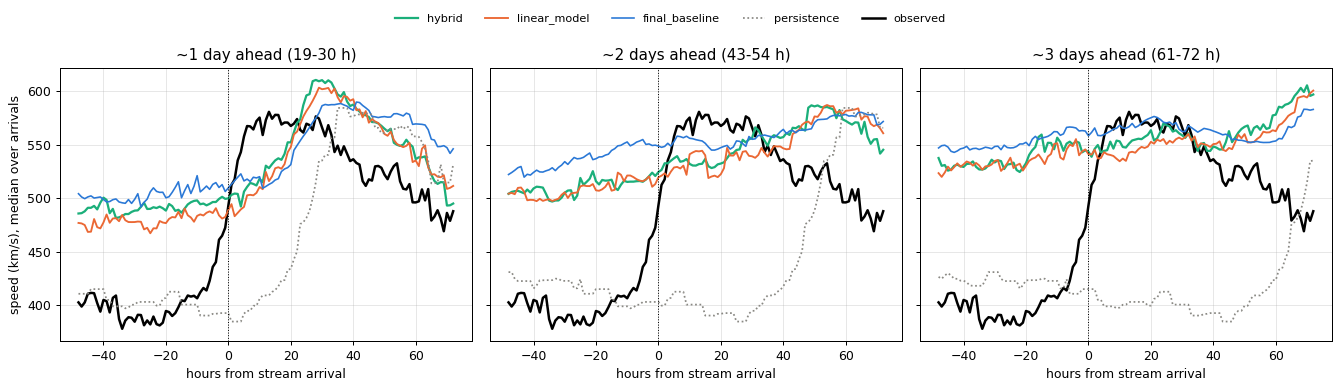

In [8]:
eval_arrivals = arrivals[(arrivals >= TRAIN_END + pd.Timedelta(days=3)) & (arrivals < EVAL_END)]
valid = t0s.values[:, None] + lead[None, :] * np.timedelta64(1, "h")
lead_grid = np.broadcast_to(lead, valid.shape)
groups = {"~1 day ahead (19-30 h)": (19, 30), "~2 days ahead (43-54 h)": (43, 54),
          "~3 days ahead (61-72 h)": (61, 72)}
rel_hours = np.arange(-48, 73)
epoch, capture = {}, {}
for gname, (lo, hi) in groups.items():
    stacks = {m: [] for m in MODELS}
    caps = {m: [] for m in MODELS}
    obs_stack = []
    for a in eval_arrivals:
        rel = (valid - a.tz_convert(None).to_datetime64()) / np.timedelta64(1, "h")
        sel = (rel >= -48) & (rel <= 72) & (lead_grid >= lo) & (lead_grid <= hi)
        obs = series.reindex(a + pd.to_timedelta(rel_hours, unit="h")).to_numpy()
        obs_stack.append(obs)
        rise_obs = np.nanmean(obs[(rel_hours >= 12) & (rel_hours <= 36)]) - np.nanmean(
            obs[(rel_hours >= -36) & (rel_hours <= -12)])
        for m in MODELS:
            df = pd.DataFrame({"rel": rel[sel].round().astype(int), "f": forecasts[m][sel]})
            curve = df.groupby("rel")["f"].mean().reindex(rel_hours)
            stacks[m].append(curve.to_numpy())
            after = curve[(curve.index >= 12) & (curve.index <= 36)].mean()
            before = curve[(curve.index >= -36) & (curve.index <= -12)].mean()
            caps[m].append((after - before) / rise_obs)
    epoch[gname] = ({m: np.nanmedian(np.array(stacks[m]), axis=0) for m in MODELS},
                    np.nanmedian(np.array(obs_stack), axis=0))
    capture[gname] = {m: np.nanmedian(caps[m]) for m in MODELS}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, (gname, (curves, obs)) in zip(axes, epoch.items(), strict=True):
    ax.plot(rel_hours, obs, color="k", lw=2)
    for m in MODELS:
        ax.plot(rel_hours, curves[m], **STYLE[m])
    ax.axvline(0, color="k", lw=0.8, ls=":")
    ax.set(title=gname, xlabel="hours from stream arrival")
axes[0].set_ylabel("speed (km/s), median over arrivals")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=2), "observed")])
print(f"{len(eval_arrivals)} non-CME stream arrivals")
fmt(pd.DataFrame(capture).T.rename(columns=lambda m: f"{m}: share of rise"))

## 5. What the trees do

### 5.1 The size of the corrections

The trees' correction to the linear forecast (hybrid − linear, km/s), by lead: the median and the
10–90% range over all runs, and the mean by regime.

,mean 6 h,mean 24 h,mean 72 h,mean |correction|
CME,9.9,9.44,2.2,19.8
possible CME,-2.76,-5.38,-13,14.7
stream arrival,10.8,10.6,8.21,15.9
fast stream,2.21,0.414,-15.1,12.1
slow wind,-1.39,-1.79,-2.73,11
intermediate,-0.748,-1.73,-9.2,13


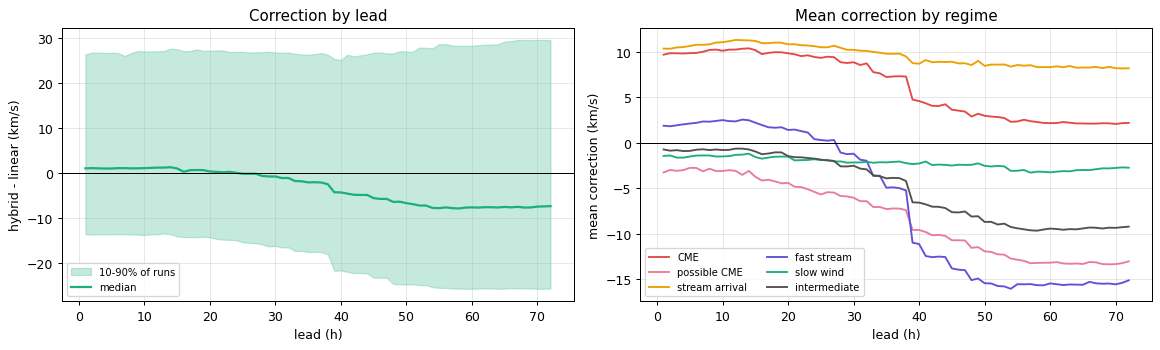

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
q10, q50, q90 = np.nanquantile(correction, [0.1, 0.5, 0.9], axis=0)
axes[0].fill_between(lead, q10, q90, color=STYLE["hybrid"]["color"], alpha=0.25,
                     label="10-90% of runs")
axes[0].plot(lead, q50, color=STYLE["hybrid"]["color"], lw=1.8, label="median")
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set(xlabel="lead (h)", ylabel="hybrid - linear (km/s)", title="Correction by lead")
axes[0].legend(fontsize=8)
for g in ev.REGIMES:
    sel = (regime == g).to_numpy()
    axes[1].plot(lead, correction[sel].mean(axis=0), color=REGIME_COLORS[g], lw=1.5, label=g)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(xlabel="lead (h)", ylabel="mean correction (km/s)", title="Mean correction by regime")
axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout()
summary = pd.DataFrame({
    g: {f"mean {k} h": correction[(regime == g).to_numpy(), k - 1].mean() for k in (6, 24, 72)}
    | {"mean |correction|": np.abs(correction[(regime == g).to_numpy()]).mean()}
    for g in ev.REGIMES
}).T
fmt(summary)

### 5.2 The trees

The table counts how often each input is used in a split of the 100 depth-2 trees. The gain
share comes from the selection on the training folds (`xgboost_hybrid_config.json`, before taming).
The root split of each tree (its most important cut) is counted by input. The last lines check the
untamed rule's condition (5-day M-flare count ≥ 48): how rare it is, and where the tamed trees now
split on the flare count.

In [10]:
trees = hybrid.trees
cols = list(hybrid.config.columns)
inner = trees.left >= 0
used = pd.Series([cols[f] for f in trees.feature[inner]]).value_counts()
gain = pd.Series(json.loads(config_path("linear").read_text())["selection"]["gain_share"])
usage = pd.DataFrame({"splits": used, "gain share (folds)": gain}).fillna(0)
usage = usage[usage["splits"] > 0].sort_values("splits", ascending=False)
display(fmt(usage))
roots = pd.DataFrame({"tree": range(trees.n_trees),
                      "root split": [cols[trees.feature[r]] for r in trees.roots],
                      "threshold": [float(trees.threshold[r]) for r in trees.roots]})
display(roots["root split"].value_counts().rename("trees with this root split").to_frame().T)

from training.datasets import load_train  # noqa: E402
from training.xgboost_model import CACHE_DIR, hourly_runs  # noqa: E402

train_t0s = hourly_runs(load_train())
train_tab = feature_table(train_t0s, tuple(INPUTS), CACHE_DIR / "table_train.pkl")
# how rare is the far side of each solar-activity split? (the 4-year flare rule's failure)
activity = [f for f in TREE_FEATURES if f.startswith(("m_flares_", "xray_peak_", "f107_"))]
for f in activity:
    th = sorted({float(t) for c, t in zip(trees.feature[inner], trees.threshold[inner],
                                         strict=True) if cols[c] == f})
    if not th:
        print(f"{f}: not split on")
        continue
    top = max(th)
    print(f"{f}: split at {[round(t, 2) for t in th]}; at or above the highest split: "
          f"{(train_tab[f] >= top).mean():.1%} of training hours, "
          f"{(table[f] >= top).mean():.1%} of eval runs")

,splits,gain share (folds)
f107_mean_24h,50,0.0775
ch_cm_at_48h,46,0.0434
last,43,0.0372
lead,42,0.0532
log_p310_mean_1h,40,0.0195
rec_27d,38,0.0728
xray_peak_max_72h,35,0.0614
ch_cm_at_0h,35,0.0437
polarity_lag27_72h,34,0.0356
ch_cm_at_24h,33,0.0304


root split,rec_27d,rec_13.5d,bt_max_6h,log_p310_mean_1h,last,m_flares_count_72h,ch_east_at_24h,polarity_lag27_72h,ch_cm_at_0h,ch_cm_at_24h,density_lag13_72h,density_slope_24h,polarity_mean_48h,xray_peak_max_72h,ch_disk_at_0h,f107_mean_24h,ch_east_at_0h,log_t_ratio_mean_1h,pressure_lag27_72h
trees with this root split,13,10,9,8,7,6,6,6,5,5,5,4,4,3,3,2,2,1,1


m_flares_count_72h: split at [6.0, 8.0, 10.0, 11.0, 13.0, 14.0, 15.0, 16.0, 18.0, 19.0]; at or above the highest split: 1.2% of training hours, 2.3% of eval runs
xray_peak_max_72h: split at [-5.63, -5.44, -5.28, -5.26, -4.75, -4.4, -4.38, -4.21, -4.13, -4.13, -4.02, -3.96, -3.95, -3.73, -3.7, -3.68]; at or above the highest split: 2.1% of training hours, 4.1% of eval runs
f107_mean_24h: split at [67.1, 68.0, 68.2, 69.1, 73.1, 74.4, 75.3, 76.0, 103.8, 119.3, 127.5, 134.1, 139.6, 144.5, 147.5, 151.7, 155.3, 155.8, 161.5, 164.6, 174.9, 178.1, 188.1, 196.2, 199.7, 209.3, 234.3, 238.3]; at or above the highest split: 1.8% of training hours, 0.3% of eval runs


### 5.3 Ablation: which tree inputs matter on the eval year

The linear anchor is kept fixed, and one tree input at a time is marked missing for every run,
exactly as a live run with that feed down would see it:
- **most inputs:** the trees take their learned default branch;
- **the three never missing in training** (M-flare count, 120 h peak flare flux, 7-day F10.7): the input takes its training median, because their default branch was never trained (`impute_values`, section 5.2).

The change is in per-run mean and median TIMSE and pooled TIMSE relative to the full hybrid;
positive means the input helps. "All regressors missing" leaves the trees only the lead, the speed
terms and the anchor. This analyses the fitted model; it is not a refit.

In [11]:
def without(names):
    xa = x.copy()
    for c in names:
        xa[:, INPUTS.index(c)] = np.nan
    rows, _ = hybrid.rows(values, pos, xa, anchor=anchor)  # imputes as live
    return np.clip(anchor + trees.predict(rows).reshape(len(pos), HORIZON), 200, 1500)


def scores(f):
    s = run_timse(f, actual)
    return np.nanmean(s), np.nanmedian(s), timse(actual, f)


print("imputed with the training median when missing:", hybrid.impute_values)
full = scores(forecasts["hybrid"])
groups_ab = {c: [c] for c in TREE_FEATURES}
groups_ab["all regressors missing"] = TREE_FEATURES
rows_ab = {}
for name, members in groups_ab.items():
    s = scores(without(members))
    rows_ab[name] = {"per-run mean, worse by": s[0] / full[0] - 1,
                     "per-run median, worse by": s[1] / full[1] - 1,
                     "pooled TIMSE, worse by": s[2] / full[2] - 1}
ablation = pd.DataFrame(rows_ab).T.sort_values("pooled TIMSE, worse by", ascending=False)
fmt(ablation)

imputed with the training median when missing: {'m_flares_count_72h': 0.0, 'xray_peak_max_72h': -5.634070873260498, 'f107_mean_24h': 81.0}


,"per-run mean, worse by","per-run median, worse by","pooled TIMSE, worse by"
log_p310_mean_1h,0.012,-0.025,0.0325
density_lag13_72h,0.031,-0.118,0.0276
icme_mean_48h,0.011,-0.00627,0.0243
pressure_lag27_72h,0.0102,-0.04,0.0217
b_var_mean_48h,0.00206,-0.000484,0.00837
ch_disk_at_0h,0.00324,0.0198,0.00816
bt_max_6h,0.00639,-0.0238,0.00805
ch_cm_at_72h,0.00235,-0.00834,0.00748
bt_mean_1h,0.00539,-0.0039,0.00661
density_slope_24h,0.00319,0.00425,0.00539


### 5.4 The coronal-hole effect

The linear model over-forecast when the central-meridian coronal hole was large: it won only 45%
of runs in the largest quarter. The trees see the strip at several lags and can level the effect
off. The table compares the three models by quarter of the linear model's coronal-hole strip (`ch_cm_at_24h`), and on the runs without a
coronal-hole image (the linear model's submodel runs). The figure shows the mean correction at
48–72 h by strip area.

,runs,median hybrid / linear,hybrid beats linear,median hybrid / baseline,median linear / baseline,"residual 72 h, hybrid","residual 72 h, linear",mean correction 48-72 h
no image (submodel),281,0.916,0.58,0.865,0.86,-110,-104,5.53
Q1 (small),292,0.887,0.661,0.499,0.586,-120,-126,-5.9
Q2,292,0.921,0.664,0.673,0.731,-104,-110,-6.31
Q3,291,0.966,0.574,0.899,0.919,-94.8,-97.7,-2.49
Q4 (large),292,0.936,0.62,1.06,1.08,-107,-113,-5.46


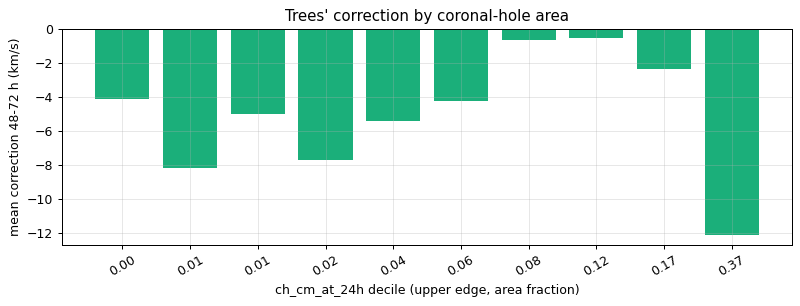

In [12]:
CH = next(f for f in linear.config.features if f.startswith("ch_cm"))
ch = table[CH]
no_image = linear.uses_fallback(x_lin)
groups_ch = pd.Series(np.where(no_image, "no image (submodel)", ""), index=t0s, dtype=object)
groups_ch[~no_image] = pd.qcut(ch[~no_image], 4, labels=["Q1 (small)", "Q2", "Q3",
                                                        "Q4 (large)"]).astype(str)
rows_ch = {}
for g in ["no image (submodel)", "Q1 (small)", "Q2", "Q3", "Q4 (large)"]:
    sel = (groups_ch == g).to_numpy()
    rows_ch[g] = {"runs": int(sel.sum()),
                  "median hybrid / linear": vs_lin[sel].median(),
                  "hybrid beats linear": (vs_lin[sel] < 1).mean(),
                  "median hybrid / baseline": vs_base[sel].median(),
                  "median linear / baseline": lin_vs_base[sel].median(),
                  "residual 72 h, hybrid": np.nanmean(residuals["hybrid"][sel, 71]),
                  "residual 72 h, linear": np.nanmean(residuals["linear_model"][sel, 71]),
                  "mean correction 48-72 h": correction[sel, 47:].mean()}
display(fmt(pd.DataFrame(rows_ch).T))

fig, ax = plt.subplots(figsize=(9, 3.5))
obs = ~no_image
bins_ch = pd.qcut(ch[obs], 10, duplicates="drop")
mc = pd.Series(correction[obs, 47:].mean(axis=1), index=t0s[obs]).groupby(bins_ch,
                                                                         observed=True).mean()
ax.bar(range(len(mc)), mc.to_numpy(), color=STYLE["hybrid"]["color"])
ax.set_xticks(range(len(mc)), [f"{iv.right:.2f}" for iv in mc.index], rotation=30)
ax.axhline(0, color="k", lw=0.8)
ax.set(xlabel=f"{CH} decile (upper edge, area fraction)",
       ylabel="mean correction 48-72 h (km/s)", title="Trees' correction by coronal-hole area")
fig.tight_layout()

### 5.5 Taming: leaf support

On 4 years, the selected hybrid's dominant rule rested on one flare-rich episode, which the
folds could not test out of sample. The 9-year selection repeats the check. Each variant is judged
on two things, both from training data only:
- its **fold score**;
- its **leaf support**: the number of distinct training days whose runs reach each leaf.

A leaf reached on fewer than 30 days (about a solar rotation) rests on a single episode. The rule,
fixed before any variant was scored, was to keep the best fold score among the variants with no
such leaf (`python -m training.xgboost_model tame`).

The table lists every variant:
- **min_leaf_days:** the support of its weakest leaf;
- **max_thin_correction:** the largest correction any training run gets from leaves under 30 days.

On 9 years the selected setting (minimum leaf weight 100) had its weakest leaf reached on a
single training day, and thin leaves moved some runs by up to 297 km/s. The figure shows the leaf
support of the shipped (tamed) trees.

,min_child_weight,n_trees,objective,fold1,fold2,fold3,fold4,fold5,fold6,min_leaf_days,thin_leaves,max_thin_correction
variant,,,,,,,,,,,,
shipped,100,100,0.425,0.395,0.363,0.492,0.464,0.534,0.336,1,644,297
min_child_weight 1000,1000,50,0.43,0.399,0.365,0.511,0.465,0.541,0.336,2,194,247
min_child_weight 3000,3000,100,0.427,0.396,0.369,0.489,0.465,0.546,0.336,10,137,168
min_child_weight 5000,5000,50,0.427,0.402,0.366,0.484,0.458,0.555,0.336,17,29,55.7
min_child_weight 10000,10000,100,0.426,0.394,0.361,0.492,0.46,0.555,0.333,43,0,0
min_child_weight 20000,20000,100,0.428,0.396,0.355,0.499,0.466,0.552,0.34,95,0,0
min_child_weight 40000,40000,200,0.429,0.392,0.353,0.502,0.469,0.554,0.344,170,0,0
"min_child_weight 10000, depth 3",10000,100,0.427,0.402,0.36,0.493,0.457,0.552,0.337,43,0,0
"no flare count, mcw 100",100,100,0.425,0.395,0.363,0.492,0.464,0.534,0.336,1,644,297


shipped trees: 852 leaves; the weakest is reached on 43 training days; median 195


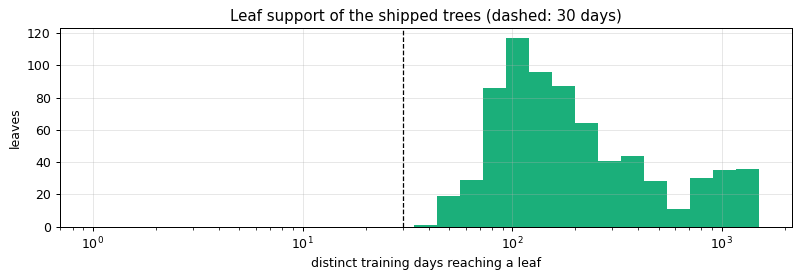

In [13]:
from training.xgboost_model import leaf_support  # noqa: E402

taming = pd.read_csv("xgboost_hybrid_taming.csv").set_index("variant")
fold_cols = [c for c in taming.columns if c.startswith("fold")]
display(fmt(taming[["min_child_weight", "n_trees", "objective", *fold_cols,
                    "min_leaf_days", "thin_leaves", "max_thin_correction"]]))
tx_inputs = train_tab[INPUTS].to_numpy(dtype=np.float32)
train_series = load_train()
support = leaf_support(hybrid, train_series.to_numpy(dtype=float),
                       train_series.index.get_indexer(train_t0s), tx_inputs, train_t0s)
print(f"shipped trees: {len(support)} leaves; the weakest is reached on {support['days'].min()} "
      f"training days; median {support['days'].median():.0f}")
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.hist(support["days"], bins=np.logspace(0, np.log10(1500), 30), color=STYLE["hybrid"]["color"])
ax.axvline(30, color="k", lw=1, ls="--")
ax.set(xscale="log", xlabel="distinct training days reaching a leaf", ylabel="leaves",
       title="Leaf support of the shipped trees (dashed: 30 days)")
fig.tight_layout()

## 6. Through the year and the biggest differences

### 6.1 Month by month

Per-run mean TIMSE by month, the hybrid's win share against the linear model, and each month's
share of the year's change in the per-run total, hybrid minus linear (negative = a gain for the
hybrid; the column sums to −1).

,runs,hybrid mean,linear mean,baseline mean,hybrid beats linear,CME runs,share of change vs linear
2025-10,48,1.45e+06,1.26e+06,1.71e+06,0.604,0,0.0536
2025-11,120,6.42e+06,7.52e+06,8.16e+06,0.658,0.4,-0.762
2025-12,124,1.65e+06,1.66e+06,1.53e+06,0.548,0.242,-0.00211
2026-01,124,7.68e+06,7.77e+06,8.6e+06,0.565,0.25,-0.0604
2026-02,112,1.13e+06,1.16e+06,1.47e+06,0.589,0.277,-0.0218
2026-03,124,1.38e+06,1.38e+06,1.33e+06,0.556,0.355,-0.000983
2026-04,120,1.19e+06,1.08e+06,1.35e+06,0.5,0.125,0.0796
2026-05,124,7.94e+05,9.52e+05,1.29e+06,0.758,0.129,-0.113
2026-06,120,1.19e+06,1.3e+06,1.54e+06,0.775,0.383,-0.076
2026-07,124,7.48e+05,8.02e+05,9.89e+05,0.637,0.0645,-0.0387


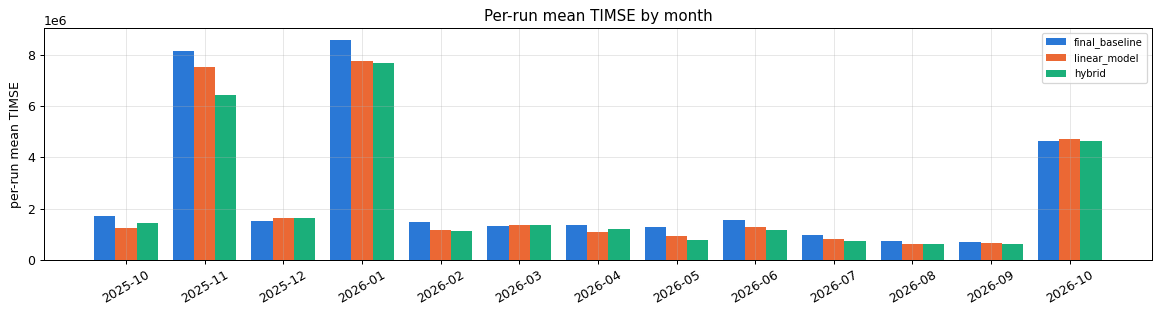

In [14]:
month = pd.Series(t0s.strftime("%Y-%m"), index=t0s)
monthly = pd.DataFrame({
    "runs": month.value_counts().sort_index(),
    "hybrid mean": run_scores["hybrid"].groupby(month).mean(),
    "linear mean": run_scores["linear_model"].groupby(month).mean(),
    "baseline mean": run_scores["final_baseline"].groupby(month).mean(),
    "hybrid beats linear": (vs_lin < 1).groupby(month).mean(),
    "CME runs": (regime == "CME").groupby(month).mean(),
    "share of change vs linear": diff.groupby(month).sum() / abs(total_change),
})
fig, ax = plt.subplots(figsize=(13, 3.6))
xm = np.arange(len(monthly))
for off, m, c in ((-0.27, "baseline mean", "final_baseline"), (0, "linear mean", "linear_model"),
                  (0.27, "hybrid mean", "hybrid")):
    ax.bar(xm + off, monthly[m], 0.27, color=STYLE[c]["color"], label=c)
ax.set_xticks(xm, monthly.index, rotation=30)
ax.set(ylabel="per-run mean TIMSE", title="Per-run mean TIMSE by month")
ax.legend(fontsize=8)
fig.tight_layout()
fmt(monthly)

### 6.2 Where the trees help and hurt most

The ten runs where the hybrid gains most over the linear model (largest drop in per-run TIMSE),
and the ten where it loses most. Four examples are plotted: the two largest gains and the two
largest losses. Each panel shows the 48 h before `t0`, then the 72 h forecasts.

Largest gains over the linear model:


,regime,hybrid,linear,baseline,hybrid - linear,hybrid / linear,mean correction,peak observed,ch_cm_at_24h
2026-01-19 18,CME,1.57e+08,1.82e+08,1.89e+08,-2.42e+07,0.867,36.8,1.08e+03,0.179
2025-11-11 18,CME,4.38e+07,6.37e+07,5.58e+07,-1.99e+07,0.688,61.6,940,nan
2026-01-19 12,CME,1.26e+08,1.44e+08,1.56e+08,-1.82e+07,0.873,32.8,1.08e+03,0.213
2025-11-11 12,CME,4.17e+07,5.73e+07,5.26e+07,-1.56e+07,0.727,50.5,940,nan
2026-01-20 00,CME,3.9e+07,4.85e+07,3.16e+06,-9.45e+06,0.805,-43,996,0.193
2025-11-05 12,CME,1.73e+07,2.67e+07,2.29e+07,-9.4e+06,0.648,49.3,830,nan
2025-11-12 06,CME,2.19e+07,3.11e+07,8.77e+07,-9.2e+06,0.704,42.9,940,nan
2025-11-05 06,CME,1.76e+07,2.58e+07,2.17e+07,-8.19e+06,0.682,40.3,830,nan
2025-11-23 00,stream arrival,1.29e+07,2.1e+07,1.66e+07,-8.08e+06,0.615,53.8,804,nan
2025-11-05 18,CME,1.5e+07,2.31e+07,2.19e+07,-8.04e+06,0.651,49.7,830,nan


Largest losses to the linear model:


,regime,hybrid,linear,baseline,hybrid - linear,hybrid / linear,mean correction,peak observed,ch_cm_at_24h
2026-01-18 06,CME,4.42e+07,3.39e+07,5.27e+07,1.03e+07,1.3,-28.7,1.08e+03,0.249
2026-01-18 12,CME,4.38e+07,3.43e+07,5.78e+07,9.53e+06,1.28,-27.7,1.08e+03,0.286
2026-01-18 00,CME,4.53e+07,3.6e+07,5.01e+07,9.3e+06,1.26,-25.2,1.08e+03,0.21
2025-11-10 18,CME,5.03e+07,4.19e+07,4.58e+07,8.39e+06,1.2,-22.7,940,nan
2026-01-18 18,CME,4.94e+07,4.12e+07,6.58e+07,8.23e+06,1.2,-25.4,1.08e+03,0.303
2026-01-19 00,CME,5.53e+07,4.71e+07,7.17e+07,8.15e+06,1.17,-29.6,1.08e+03,0.306
2025-11-10 12,CME,4.87e+07,4.16e+07,4.59e+07,7.1e+06,1.17,-15.4,940,nan
2025-11-10 06,CME,4.28e+07,3.61e+07,4.2e+07,6.71e+06,1.19,-18.2,940,nan
2026-01-17 18,CME,4.39e+07,3.84e+07,4.81e+07,5.52e+06,1.14,-13.8,1.08e+03,0.163
2025-11-10 00,CME,3.01e+07,2.64e+07,3.07e+07,3.7e+06,1.14,-9.9,940,nan


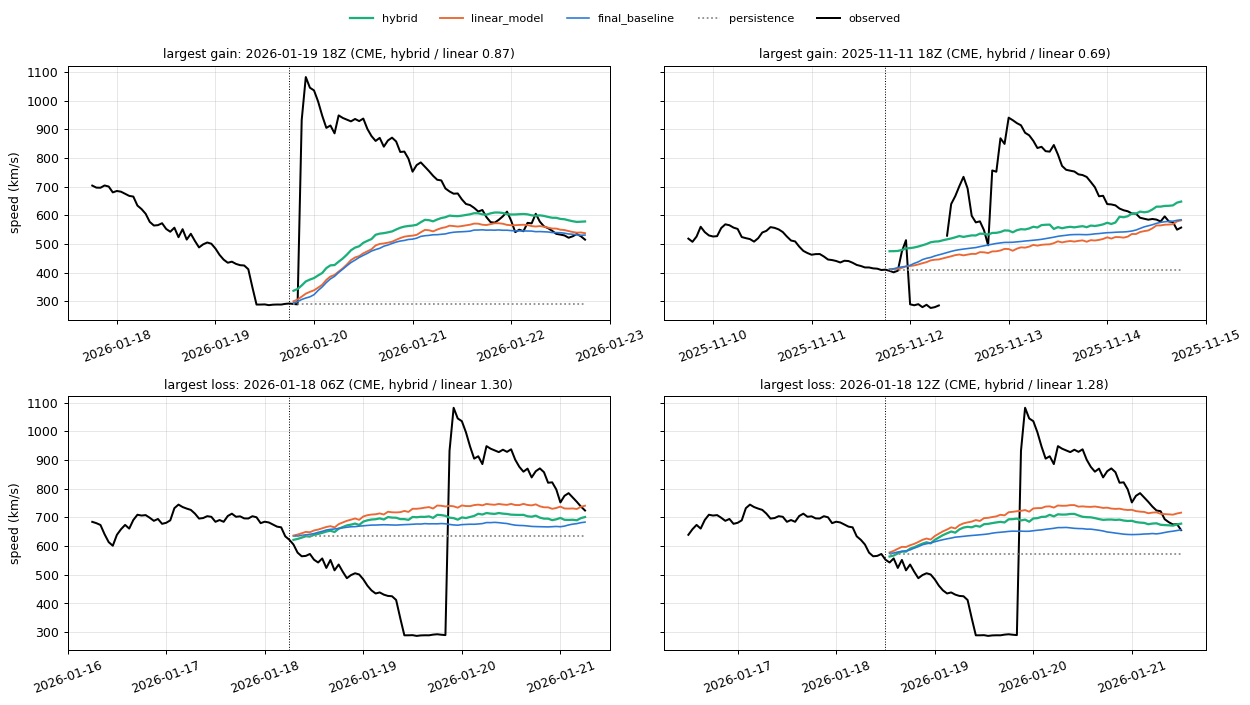

In [15]:
info = pd.DataFrame({
    "regime": regime,
    "hybrid": run_scores["hybrid"],
    "linear": run_scores["linear_model"],
    "baseline": run_scores["final_baseline"],
    "hybrid - linear": diff,
    "hybrid / linear": vs_lin,
    "mean correction": correction.mean(axis=1),
    "peak observed": np.nanmax(actual, axis=1),
    CH: ch,
})
shown = info.copy()
shown.index = shown.index.strftime("%Y-%m-%d %H")
print("Largest gains over the linear model:")
display(fmt(shown.sort_values("hybrid - linear").head(10)))
print("Largest losses to the linear model:")
display(fmt(shown.sort_values("hybrid - linear", ascending=False).head(10)))

picks = ([("gain", t) for t in info["hybrid - linear"].nsmallest(2).index]
         + [("loss", t) for t in info["hybrid - linear"].nlargest(2).index])
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharey=True)
for ax, (label, t0) in zip(axes.flat, picks, strict=True):
    k = t0s.get_loc(t0)
    hist = series[t0 - pd.Timedelta(hours=48): t0 + pd.Timedelta(hours=HORIZON)]
    ax.plot(hist.index, hist, color="k", lw=1.6)
    times = t0 + pd.to_timedelta(lead, unit="h")
    for m in MODELS:
        ax.plot(times, forecasts[m][k], **STYLE[m])
    ax.axvline(t0, color="k", lw=0.8, ls=":")
    ax.set_title(f"largest {label}: {t0:%Y-%m-%d %H}Z ({regime.iloc[k]}, "
                 f"hybrid / linear {vs_lin.iloc[k]:.2f})", fontsize=10)
    ax.tick_params(axis="x", labelrotation=20)
for ax in axes[:, 0]:
    ax.set_ylabel("speed (km/s)")
fig.tight_layout()
model_legend(fig, [(Line2D([], [], color="k", lw=1.6), "observed")])

## 7. Findings

Eval year 2025-10-20 → 2026-10-20, 1,448 runs. The model is the 9-year hybrid: the 9-year linear
model plus 100 depth-4 trees with a minimum leaf weight of 10,000. The 4-year hybrid's numbers come
from `docs/xgboost_model.md`.

### (i) Overall: the trees now help on most runs

| | 9-year hybrid | 4-year hybrid | 9-year linear | Final baseline |
|---|---|---|---|---|
| Pooled TIMSE | 4.73 × 10⁷ | 4.36 × 10⁷ | 4.82 × 10⁷ | 5.58 × 10⁷ |
| Per-run mean | 2.22 × 10⁶ | 2.22 × 10⁶ | 2.34 × 10⁶ | 2.59 × 10⁶ |
| Per-run median | 6.45 × 10⁵ | 7.04 × 10⁵ | 6.67 × 10⁵ | 8.45 × 10⁵ |
| Runs won against its linear anchor | **62%** | 52% | | |
| Runs won against the baseline | 66% | 64% | | |

- **The trees now improve the typical run.** Against its linear anchor the hybrid is 3–11% lower from p10 to the median. The 4-year hybrid was worse there.
- **The cost is at the top of the distribution:** p75 is 7% higher and p99 17% higher than the linear model's.
- **Against the final baseline:** median 24% lower, per-run mean 14% lower.
- **By month:** the hybrid wins more runs than the linear model in 12 of 13 months (one is a tie). The per-run-mean gain over the linear model is concentrated in November 2025 (76% of it), the month of three CMEs.

### (ii) By regime

| Regime | Median hybrid / linear | Hybrid wins vs linear | Pooled hybrid / linear |
|---|---|---|---|
| CME | 0.97 | 53% | 0.98 |
| possible CME | 0.87 | 75% | 0.94 |
| stream arrival | 1.01 | 48% | **0.79** |
| fast stream | 0.87 | 75% | 0.89 |
| slow wind | 0.92 | 68% | 1.08 |
| intermediate | 0.89 | 69% | 0.90 |

- **Stream arrivals:** the big ones improve most (pooled −21%). The hybrid reproduces 49% of the rise 1 day ahead and 10% 3 days ahead, against 41% and 6% for the linear model.
- **Quiet wind:** typical runs improve, but the 72 h over-forecast barely moves (−151 km/s in slow wind, −153 in intermediate wind, against −154 and −162 for the linear model).

### (iii) What the trees learned

- **The corrections now depend on the lead.** The lead is split on 42 times, where the 4-year trees never used it. In CME runs the correction is +10 km/s at 6 h and +2 at 72 h; in fast streams it is +2 at 6 h and −15 at 72 h.
- **Leaf support:** all 852 leaves are reached on at least 43 training days (median 195).
- **No rule rests on one episode.** For every solar-activity input, the highest split is exceeded in only 1–2% of training hours, and every leaf has at least 43 days of support.
- **The leading root splits:** the 27-day and 13.5-day recurrence means, Bt (6 h maximum), EPAM 310 keV and the last speed. The trees refine the speed history more than the solar inputs.
- **Ablation** (each input missing):
  - **most useful:** EPAM 310 keV, the 13.5-day density lag, the ICME share and the 27-day pressure lag help pooled TIMSE by 2–3%;
  - **trade-offs, as before:** the 27-day polarity lag and the coronal-hole strips (0 h, 24 h) cost pooled TIMSE (up to 6% for the polarity lag) but help the median (up to 17%).

### (iv) Coronal holes

- **The trees now lower forecasts when holes are large:** about −5 km/s at 48–72 h in the largest quarter of strip area. The hybrid beats the linear model in 62% of those runs, though both are still slightly worse than the baseline there (median ratio 1.06).
- **Runs without an image:** the trees add only +5.5 km/s (the 4-year trees added +18.5) and win 58% against the linear model.

### (v) Where the trees hurt: the eve of the big CMEs

- **The largest losses to the linear model** are the runs on 18 January 2026 and 10 November 2025, the day before the two largest CMEs. The trees lowered the forecast by 15–30 km/s in quiet-looking wind just before the arrival (up to 1.3× the linear model's TIMSE).
- **They help on the CME runs themselves:** they gain up to 30% once the CME has started.
- **The extreme-Bt run** of 2026-01-20 00Z (61 nT) is partly fixed by the trees (−43 km/s), but it is still 12× the baseline's TIMSE. A cap on the linear model's regressors would address it at the source.

### What this means

1. **With 9 years the hybrid is the best model on the median, the per-run mean and the win rate.** Pooled TIMSE is still dominated by a few CME runs, where the 4-year hybrid happened to do better.
2. **Next fixes, chosen on the folds:**
   - cap the linear model's regressors at a high training quantile (the 61 nT run);
   - look at the pre-CME downward corrections.
3. **The 72 h quiet-wind level is unchanged** for every model so far. It needs inputs that predict the absence of a stream.

### Caveats

- **Eval-year looks:** the hybrid family has now been scored three times on the eval year. Each version was chosen on the training folds, but the comparisons are no longer independent.
- **Regimes** come from the in-situ CME catalogue and use the observed future speed: a diagnostic, not an input.